**Méteo et Polution - Projet Pyhton**

In [67]:
# Liste des imports
from pathlib import Path

import requests
import pandas as pd
from src import fct
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

**Dataset Meteo**

In [68]:
import importlib
from src import fct

importlib.reload(fct)

df_raw_meteo = fct.meteo_dataset_extraction()

print("Dimensions :", df_raw_meteo.shape)
display(df_raw_meteo.head())

Dimensions : (8760, 24)


,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,snow_depth,surface_pressure,...,cloud_cover_high,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m,wind_gusts_10m,shortwave_radiation,soil_temperature_0_to_7cm,soil_moisture_0_to_7cm,is_day
0,2025-09-01T00:00,14.8,89,12.9,14.4,0.0,0.0,0.0,0.0,1003.6,...,100,8.7,198,18.8,209,18.0,0.0,16.4,0.170,0
1,2025-09-01T01:00,15.2,91,13.7,15.1,0.1,0.1,0.0,0.0,1004.2,...,98,8.2,195,17.3,216,16.6,0.0,16.4,0.161,0
2,2025-09-01T02:00,15.0,92,13.6,14.9,0.1,0.1,0.0,0.0,1003.7,...,100,8.0,207,17.2,218,17.3,0.0,16.2,0.162,0
3,2025-09-01T03:00,14.6,93,13.5,14.5,0.0,0.0,0.0,0.0,1003.7,...,100,8.5,215,18.3,223,17.3,0.0,16.0,0.162,0
4,2025-09-01T04:00,14.3,93,13.2,14.1,0.0,0.0,0.0,0.0,1003.5,...,0,8.1,215,18.1,224,18.0,0.0,15.7,0.162,0


## Exploration des données météo à Paris

Les températures correspondent aux mesures à 2 mètres du sol. Les moyennes
journalières et mensuelles sont calculées à partir des observations horaires.
Les jours et les mois sont définis en **UTC**, comme dans l'extraction.

In [69]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_meteo = df_raw_meteo.copy()

#premier tris des variables qui ne vont pas être très utile au projet

df_meteo = df_meteo.drop(columns=[
    "apparent_temperature",
    "dew_point_2m",
    "snow_depth",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "soil_temperature_0_to_7cm",
    "soil_moisture_0_to_7cm",
])

display(df_meteo.isna().sum())
display(df_meteo.dtypes)

#Transformation du format des dates, pour un meilleur gestions de celles-ci avec pandas
df_meteo["time"] = pd.to_datetime(df_meteo["time"], utc=True)
df_meteo = df_meteo.set_index("time", drop=False).sort_index()

temperature_jour = df_meteo["temperature_2m"].resample("D").mean()
temperature_mois = df_meteo["temperature_2m"].resample("MS").mean()

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
snowfall                0
surface_pressure        0
pressure_msl            0
cloud_cover             0
wind_speed_10m          0
wind_direction_10m      0
wind_speed_100m         0
wind_direction_100m     0
wind_gusts_10m          0
shortwave_radiation     0
is_day                  0
dtype: int64

time                        str
temperature_2m          float64
relative_humidity_2m      int64
precipitation           float64
rain                    float64
snowfall                float64
surface_pressure        float64
pressure_msl            float64
cloud_cover               int64
wind_speed_10m          float64
wind_direction_10m        int64
wind_speed_100m         float64
wind_direction_100m       int64
wind_gusts_10m          float64
shortwave_radiation     float64
is_day                    int64
dtype: object

### Température moyenne par jour

Chaque point de la courbe représente la moyenne des températures horaires d'une journée.

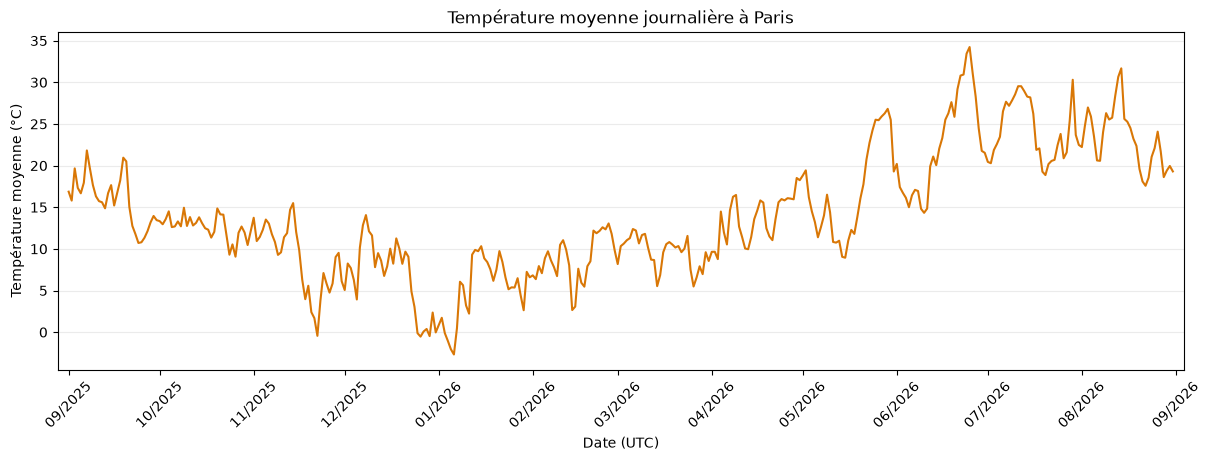

In [70]:
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.plot(temperature_jour.index, temperature_jour, color="#d97706", linewidth=1.5)

ax.set_title("Température moyenne journalière à Paris")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Température moyenne (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.margins(x=0.01)
plt.show()

### Température moyenne par mois

Chaque barre représente la moyenne de toutes les températures horaires du mois.
Les mois sont présentés dans l'ordre chronologique, de septembre 2025 à août 2026.

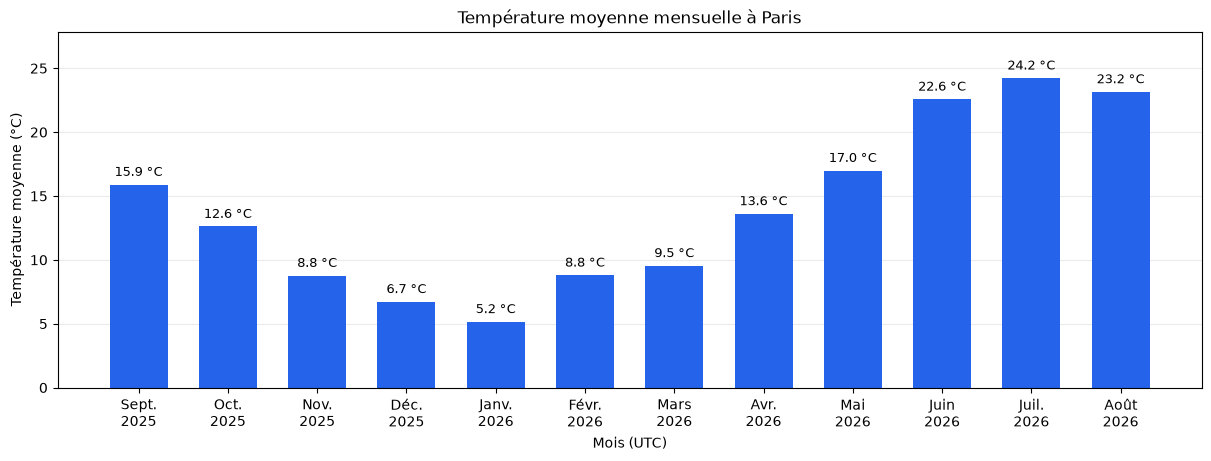

In [71]:
mois_fr = [
    "Janv.", "Févr.", "Mars", "Avr.", "Mai", "Juin",
    "Juil.", "Août", "Sept.", "Oct.", "Nov.", "Déc.",
]
labels_mois = [
    f"{mois_fr[date.month - 1]}\n{date.year}" for date in temperature_mois.index
]

fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
barres = ax.bar(labels_mois, temperature_mois.to_numpy(), color="#2563eb", width=0.65)
ax.bar_label(barres, fmt="%.1f °C", padding=4, fontsize=9)

ax.set_title("Température moyenne mensuelle à Paris")
ax.set_xlabel("Mois (UTC)")
ax.set_ylabel("Température moyenne (°C)")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.15)
plt.show()

### Pression en surface et couverture nuageuse

Chaque point correspond aux deux mesures prises à la même heure. La transparence
permet de repérer les zones où les observations se superposent.

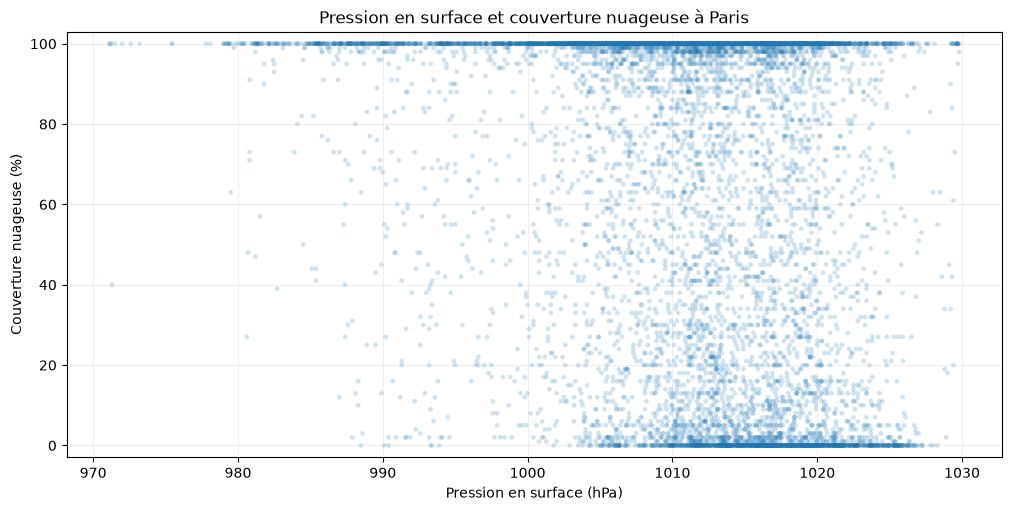

In [72]:
# Écarte seulement les heures où une des deux mesures est manquante.
pression_nuages = df_meteo[["surface_pressure", "cloud_cover"]].dropna()

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.scatter(
    pression_nuages["surface_pressure"],
    pression_nuages["cloud_cover"],
    s=12,
    alpha=0.2,
    edgecolors="none",
)

ax.set_title("Pression en surface et couverture nuageuse à Paris")
ax.set_xlabel("Pression en surface (hPa)")
ax.set_ylabel("Couverture nuageuse (%)")
ax.set_ylim(-3, 103)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Fréquence de la pluie selon la pression atmosphérique

On utilise la pression **au niveau de la mer** (`pressure_msl`), comme sur le
graphique de référence. Une heure est considérée comme pluvieuse si `rain > 0 mm`.
Pour chaque tranche de **5 hPa**, on calcule :

**Fréquence (%) = 100 × nombre d'heures pluvieuses / nombre total d'heures.**

Les points sont placés au centre des tranches. La courbe elle sert de guide
visuel, pour montrer le lien entre pluie et pression. C'est d'ailleurs comme cela que la meteo est prédite par les baromètres mécanique accrochés chez nos grands parents. A noter que les pressions les plus basses ont ici peu d'observations.

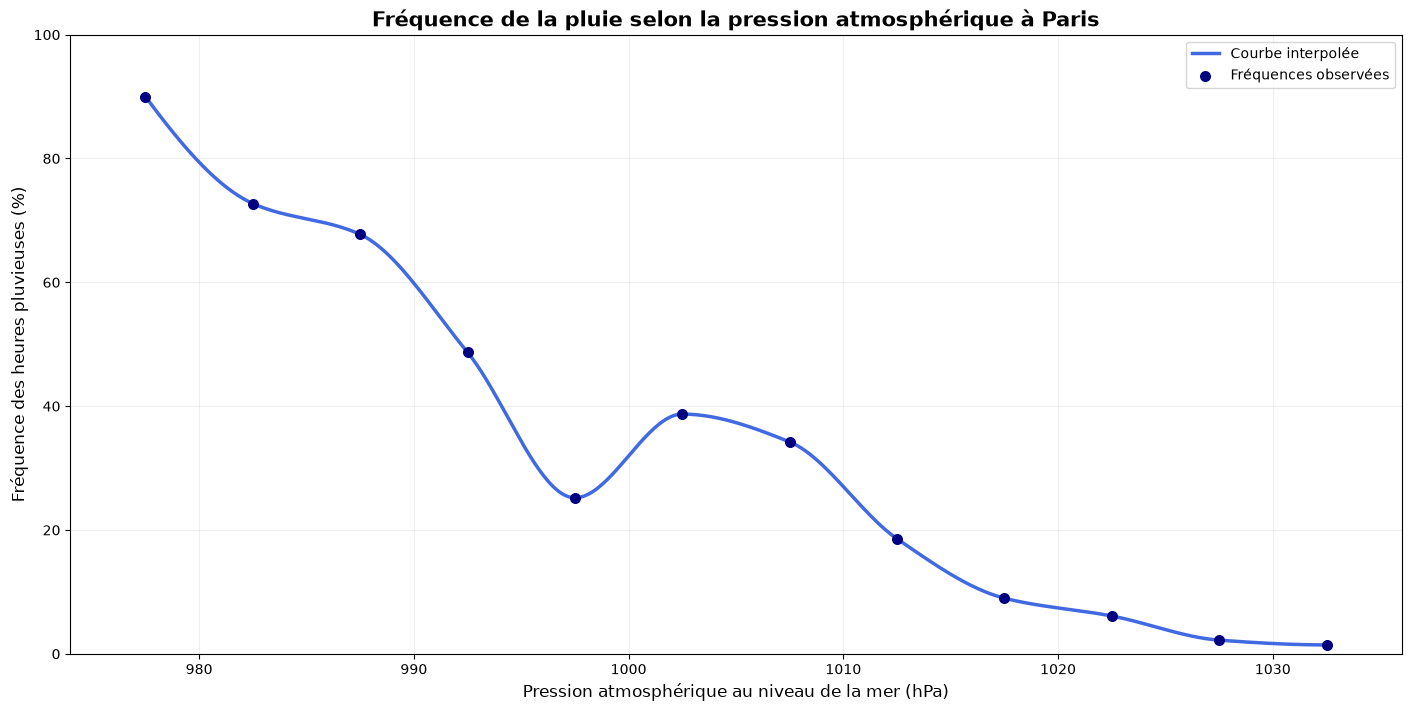

In [73]:


# On créée une nouvelle data frame pandans qui va regrouper les donners dans ces tranches de pressions
df_pluie_pression = df_meteo[["pressure_msl", "rain"]].dropna().copy()
df_pluie_pression["heure_pluvieuse"] = df_pluie_pression["rain"] > 0

# Tranches de 5 hPa couvrant toutes les pressions observées.
pas_pression = 5
pression_min = pas_pression * np.floor(df_pluie_pression["pressure_msl"].min() / pas_pression)
pression_max = pas_pression * np.floor(df_pluie_pression["pressure_msl"].max() / pas_pression)
bornes_pression = np.arange(pression_min, pression_max + 2 * pas_pression, pas_pression) #le +2 * pas pression est ici pour ne pas manquer les valeurs qu'on aurait pu oublier à cause de l'arrondit au multiple de 5 avec la fonction np.floor
df_pluie_pression["tranche_pression"] = pd.cut(
    df_pluie_pression["pressure_msl"], bins=bornes_pression, right=False
) #ici, cut va permettre d'attribuer une tranche de pression à chaque heure d'observation de pression

stats_pression_pluie = df_pluie_pression.groupby("tranche_pression").agg(
    nb_heures=("heure_pluvieuse", "size"), #nombre d'heure total observée dans la tranche
    nb_heures_pluvieuses=("heure_pluvieuse", "sum"), # nombre d'heure total dee pluie dans la tranche de pression
    frequence_pluie=("heure_pluvieuse", "mean"), # pourcentage d'heures pluviuse dans la tranche de pression
) # on regroupe les heures appartennant à une même tranche, en leur créeant des statistiques qui vont nous être utile pour créer le tableau final
stats_pression_pluie["frequence_pluie"] *= 100
stats_pression_pluie["pression_centrale"] = [
    tranche.mid for tranche in stats_pression_pluie.index
] 

pressions = stats_pression_pluie["pression_centrale"].to_numpy()
frequences = stats_pression_pluie["frequence_pluie"].to_numpy()

fig, ax = plt.subplots(figsize=(14, 7), constrained_layout=True)
if len(pressions) >= 2:
    pression_lisse = np.linspace(pressions.min(), pressions.max(), 500)
    interpolation = PchipInterpolator(pressions, frequences, extrapolate=False)
    ax.plot(
        pression_lisse, interpolation(pression_lisse),
        color="royalblue", linewidth=2.5, label="Courbe interpolée",
    ) # ici, la méthode permet d'interpoler les points créés, afin de créer une jolie courbe qui va les relier. La courbe n'a en elle même pas une vraie signification scientifique
ax.scatter(
    pressions, frequences, color="navy", s=48, zorder=3,
    label="Fréquences observées",
)

ax.set_title(
    "Fréquence de la pluie selon la pression atmosphérique à Paris",
    fontsize=15, fontweight="bold",
)
ax.set_xlabel("Pression atmosphérique au niveau de la mer (hPa)", fontsize=12)
ax.set_ylabel("Fréquence des heures pluvieuses (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.set_xlim(bornes_pression[0] - 1, bornes_pression[-1] + 1)
ax.set_yticks(np.arange(0, 101, 20))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
plt.show()